# Track2Sheet: stem → MIDI (Spotify Basic Pitch)

Transcribe a separated stem to MIDI with [Basic Pitch](https://github.com/spotify/basic-pitch)
and look at the result as a piano roll.

The stems in `docs/stems/` are `vocals`, `drums`, `bass` and `music`. There is no separate guitar
stem, so the guitar is inside **`music`**, and that is the default input. Point `STEM` at
`output/stems/<song>/guitar.wav` to use a 6-stem BS-RoFormer split.

## Setup

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import librosa
import pretty_midi
from basic_pitch import ICASSP_2022_MODEL_PATH
from basic_pitch.inference import predict
from IPython.display import Audio, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

STEM = ROOT / "docs" / "stems" / "audio [music].mp3"   # stem with the guitar in it
SONG = re.sub(r"\s*\[[^\]]+\]$", "", STEM.stem)        # "audio [music]" -> "audio"
OUT_MIDI = ROOT / "output" / "midi" / SONG / "guitar.mid"

# Basic Pitch parameters, tuned for guitar (standard tuning E2 ≈ 82 Hz up to ~fret 22 on high E)
ONSET_THRESHOLD = 0.5      # higher = fewer, more confident note starts
FRAME_THRESHOLD = 0.3      # higher = shorter / fewer sustained notes
MIN_NOTE_MS = 80           # drop notes shorter than this
MIN_FREQ = 75.0            # Hz, just below low E
MAX_FREQ = 1400.0          # Hz
FORCE = False

print(f"stem : {STEM.relative_to(ROOT)}  ({STEM.stat().st_size / 1e6:.1f} MB)")
print(f"midi : {OUT_MIDI.relative_to(ROOT)}")
print(f"model: {Path(ICASSP_2022_MODEL_PATH).name}")
display(Audio(str(STEM)))

stem : docs/stems/audio [music].mp3  (7.0 MB)
midi : output/midi/audio/guitar.mid
model: nmp


## 1. Transcribe

In [2]:
if OUT_MIDI.exists() and not FORCE:
    print(f"Already transcribed: {OUT_MIDI.relative_to(ROOT)} (set FORCE = True to redo)")
    midi = pretty_midi.PrettyMIDI(str(OUT_MIDI))
else:
    model_output, midi, note_events = predict(
        str(STEM),
        ICASSP_2022_MODEL_PATH,
        onset_threshold=ONSET_THRESHOLD,
        frame_threshold=FRAME_THRESHOLD,
        minimum_note_length=MIN_NOTE_MS,
        minimum_frequency=MIN_FREQ,
        maximum_frequency=MAX_FREQ,
        multiple_pitch_bends=False,
        melodia_trick=True,
    )
    midi.instruments[0].program = pretty_midi.instrument_name_to_program("Electric Guitar (clean)")
    midi.instruments[0].name = "guitar"
    OUT_MIDI.parent.mkdir(parents=True, exist_ok=True)
    midi.write(str(OUT_MIDI))
    print(f"Wrote {OUT_MIDI.relative_to(ROOT)}")

notes = sorted((n for inst in midi.instruments for n in inst.notes), key=lambda n: n.start)
pitches = np.array([n.pitch for n in notes])
print(f"{len(notes)} notes, {midi.get_end_time():.1f} s, "
      f"range {pretty_midi.note_number_to_name(pitches.min())}–{pretty_midi.note_number_to_name(pitches.max())}")

Already transcribed: output/midi/audio/guitar.mid (set FORCE = True to redo)
1986 notes, 217.8 s, range D#2–G#5


## 2. Visualize the MIDI

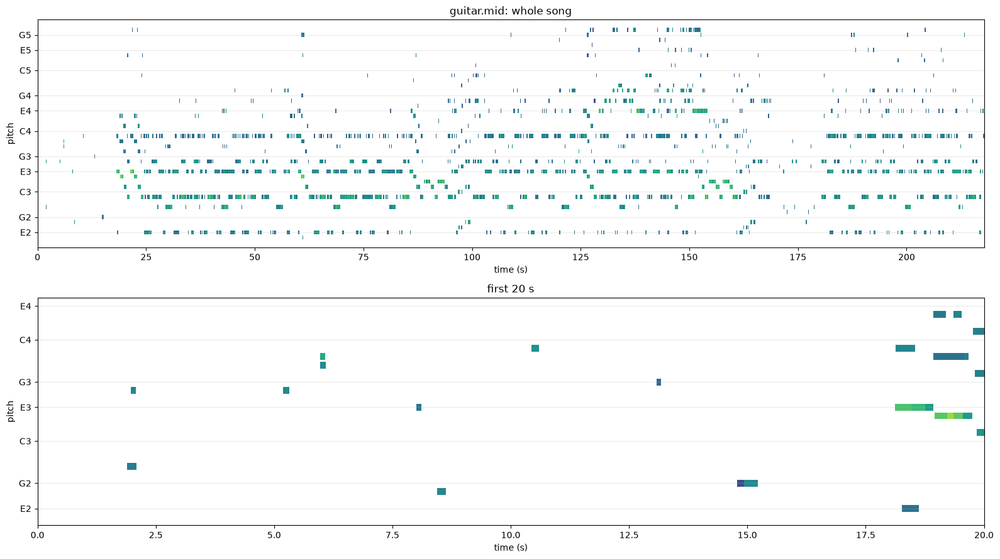

In [3]:
def piano_roll(notes, start=0.0, end=None, ax=None, title=""):
    """Draw notes as bars: x = time, y = pitch, colour = velocity."""
    end = end or max(n.end for n in notes)
    shown = [n for n in notes if n.end > start and n.start < end]
    ax = ax or plt.gca()
    cmap = plt.get_cmap("viridis")
    for n in shown:
        ax.barh(n.pitch, n.end - n.start, left=n.start, height=0.8,
                color=cmap(n.velocity / 127), edgecolor="none")
    lo, hi = min(n.pitch for n in shown) - 2, max(n.pitch for n in shown) + 2
    ticks = [p for p in range(lo, hi + 1) if p % 12 in (0, 4, 7)]  # C, E, G
    ax.set_yticks(ticks, [pretty_midi.note_number_to_name(p) for p in ticks])
    ax.set_ylim(lo, hi)
    ax.set_xlim(start, end)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("pitch")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)
    return ax


fig, (top, bottom) = plt.subplots(2, 1, figsize=(16, 9), gridspec_kw={"height_ratios": [1, 1]})
piano_roll(notes, ax=top, title=f"{OUT_MIDI.name}: whole song")
piano_roll(notes, start=0, end=20, ax=bottom, title="first 20 s")
plt.tight_layout()
plt.show()

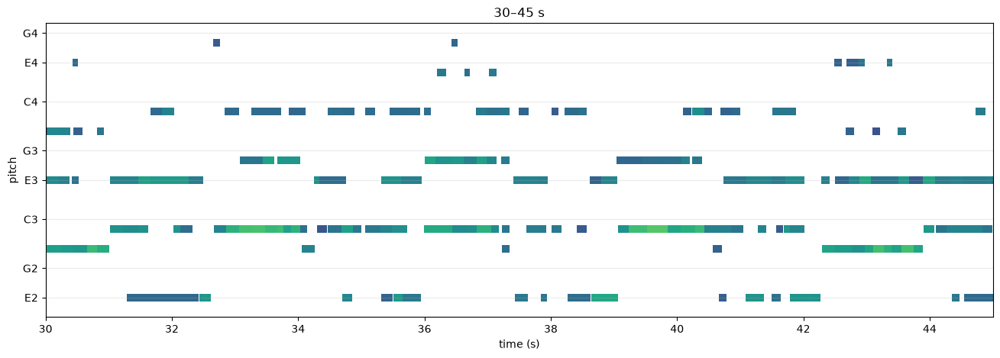

In [4]:
# Zoom in anywhere: change the window (seconds)
WINDOW = (30, 45)
plt.figure(figsize=(16, 5))
piano_roll(notes, *WINDOW, title=f"{WINDOW[0]}–{WINDOW[1]} s")
plt.show()

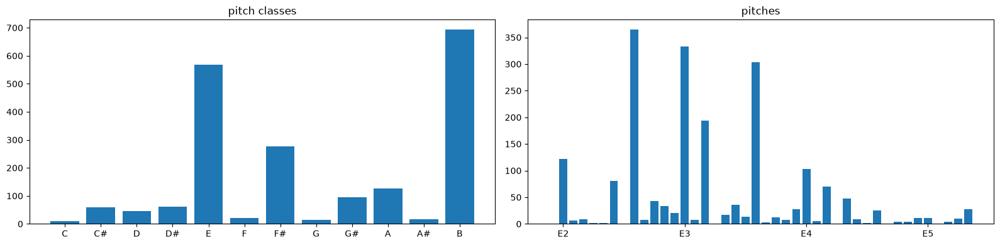

In [5]:
# Which notes show up most often (pitch class and absolute pitch)
fig, (a, b) = plt.subplots(1, 2, figsize=(16, 4))
names = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
a.bar(names, np.bincount(pitches % 12, minlength=12))
a.set_title("pitch classes")
lo, hi = pitches.min(), pitches.max()
b.bar(range(lo, hi + 1), np.bincount(pitches - lo))
ticks = [p for p in range(lo, hi + 1) if p % 12 == 4]  # E's: the guitar's open strings
b.set_xticks(ticks, [pretty_midi.note_number_to_name(p) for p in ticks])
b.set_title("pitches")
plt.tight_layout()
plt.show()

## 3. Listen to the MIDI

A simple sine synth of the transcription next to the original stem, to compare by ear.

In [6]:
SR = 22050
synth = midi.synthesize(fs=SR)
display(Audio(synth / (np.abs(synth).max() or 1), rate=SR))

## 4. Clean the MIDI

Basic Pitch's raw output has a few kinds of noise. Each cleanup step below fixes one of them and can be
turned off or tuned:

1. **Merge fragments**: a sustained note is often chopped into many short notes of the same pitch with tiny
   gaps between them. Join them back into one note.
2. **Remove harmonic ghosts**: overtones of a loud note show up as a quieter note an octave (12), an octave
   plus a fifth (19) or two octaves (24) higher, starting at the same time. Only clearly quieter ones are
   removed, because real power chords contain the octave too.
3. **Remove quiet notes**: low velocity usually means low confidence or bleed from other instruments.
4. **Remove very short notes**: blips left after merging.
5. **Max 6 notes at once**: a guitar has 6 strings. Keep the loudest notes of a chord, and let a new chord
   cut off notes still ringing from the previous one.
6. **Quantize** (optional): snap starts/ends to a grid from the detected tempo, useful for sheet music.

In [7]:
MERGE_GAP = 0.03        # s, join same-pitch notes closer than this
GHOST_INTERVALS = (12, 19, 24)
GHOST_RATIO = 0.7       # a harmonic is removed if its velocity < GHOST_RATIO x the lower note's velocity
GHOST_ONSET = 0.05      # s, how close the starts must be
MIN_VELOCITY = 35
MIN_DURATION = 0.09     # s
MAX_POLYPHONY = 6
QUANTIZE = False
GRID = 4                # subdivisions per beat when quantizing (4 = sixteenth notes)

OUT_CLEAN = OUT_MIDI.with_name("guitar_clean.mid")

In [8]:
from copy import deepcopy


def merge_fragments(notes, gap=MERGE_GAP):
    out, last = [], {}
    for n in sorted(notes, key=lambda n: n.start):
        prev = last.get(n.pitch)
        if prev is not None and n.start - prev.end <= gap:
            prev.end = max(prev.end, n.end)
            prev.velocity = max(prev.velocity, n.velocity)
        else:
            out.append(n)
            last[n.pitch] = n
    return out


def remove_ghosts(notes):
    keep = []
    for n in notes:
        ghost = any(
            o.pitch == n.pitch - k and abs(o.start - n.start) <= GHOST_ONSET
            and n.velocity < GHOST_RATIO * o.velocity and n.end <= o.end + 0.1
            for k in GHOST_INTERVALS for o in notes
        )
        if not ghost:
            keep.append(n)
    return keep


def remove_quiet(notes):
    return [n for n in notes if n.velocity >= MIN_VELOCITY]


def remove_short(notes):
    return [n for n in notes if n.end - n.start >= MIN_DURATION]


def limit_polyphony(notes, limit=MAX_POLYPHONY, chord_window=0.04):
    notes = sorted(notes, key=lambda n: n.start)
    out, i = [], 0
    while i < len(notes):
        j = i
        while j < len(notes) and notes[j].start - notes[i].start < chord_window:
            j += 1
        chord = sorted(notes[i:j], key=lambda n: -n.velocity)[:limit]
        t = min(n.start for n in chord)
        ringing = sorted((n for n in out if n.end > t), key=lambda n: n.start)
        for old in ringing[:max(0, len(ringing) + len(chord) - limit)]:  # cut the oldest
            old.end = t
        out.extend(chord)
        i = j
    return [n for n in out if n.end - n.start > 0.01]


def quantize(notes):
    y, sr = librosa.load(STEM, sr=22050)
    tempo, beats = librosa.beat.beat_track(y=y, sr=sr, units="time")
    tempo = float(np.atleast_1d(tempo)[0])
    step = 60 / tempo / GRID
    offset = beats[0] % step if len(beats) else 0.0
    snap = lambda t: offset + round((t - offset) / step) * step
    for n in notes:
        n.start, n.end = snap(n.start), max(snap(n.end), snap(n.start) + step)
    print(f"tempo {tempo:.1f} BPM, grid {step * 1000:.0f} ms")
    return merge_fragments(notes, gap=0)


steps = [("merge fragments", merge_fragments), ("remove harmonic ghosts", remove_ghosts),
         ("remove quiet notes", remove_quiet), ("remove short notes", remove_short),
         ("max 6 notes at once", limit_polyphony)]
if QUANTIZE:
    steps.append(("quantize", quantize))

clean = deepcopy(notes)
print(f"{'raw':24s} {len(clean):5d} notes")
for name, step in steps:
    before = len(clean)
    clean = step(clean)
    print(f"{name:24s} {len(clean):5d} notes  ({len(clean) - before:+d})")

out = pretty_midi.PrettyMIDI()
inst = pretty_midi.Instrument(program=pretty_midi.instrument_name_to_program("Electric Guitar (clean)"),
                              name="guitar")
inst.notes = sorted(clean, key=lambda n: (n.start, n.pitch))
out.instruments.append(inst)
out.write(str(OUT_CLEAN))
print(f"\nWrote {OUT_CLEAN.relative_to(ROOT)}")

raw                       1986 notes
merge fragments           1009 notes  (-977)
remove harmonic ghosts     950 notes  (-59)
remove quiet notes         940 notes  (-10)
remove short notes         935 notes  (-5)
max 6 notes at once        935 notes  (+0)

Wrote output/midi/audio/guitar_clean.mid


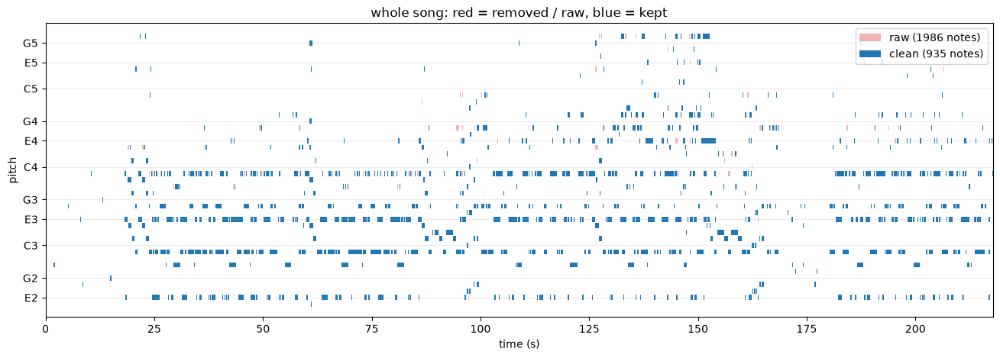

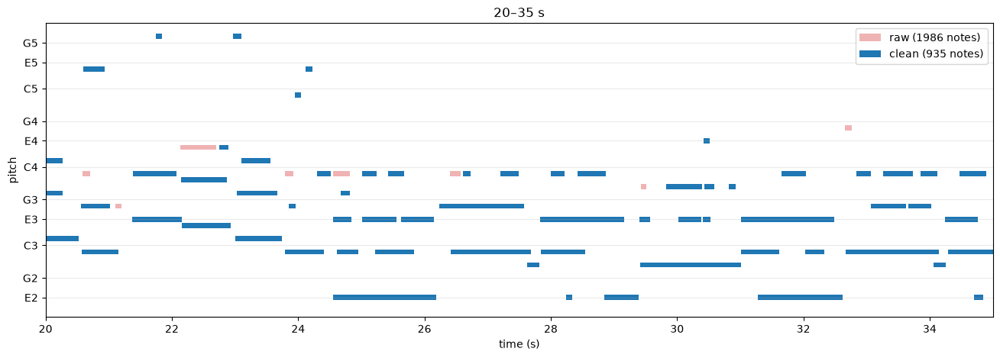

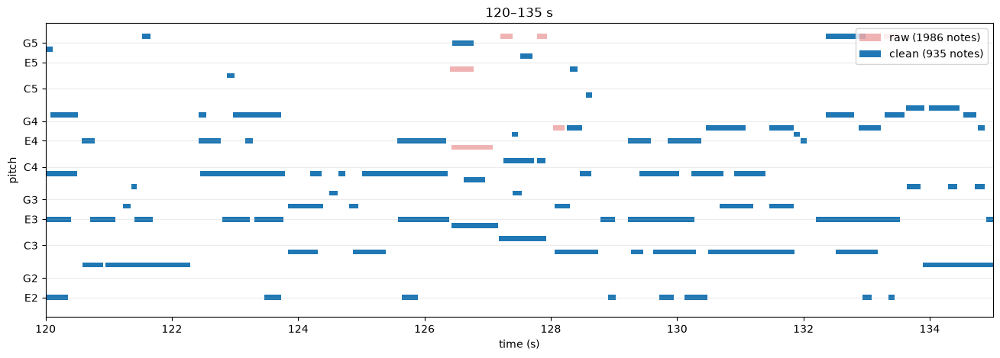

In [9]:
def compare(raw, clean, start=0.0, end=None, title=""):
    end = end or max(n.end for n in raw)
    fig, ax = plt.subplots(figsize=(16, 5))
    for n in raw:
        if n.end > start and n.start < end:
            ax.barh(n.pitch, n.end - n.start, left=n.start, height=0.8, color="tab:red", alpha=0.35)
    for n in clean:
        if n.end > start and n.start < end:
            ax.barh(n.pitch, n.end - n.start, left=n.start, height=0.8, color="tab:blue")
    ax.barh(0, 0, color="tab:red", alpha=0.35, label=f"raw ({len(raw)} notes)")
    ax.barh(0, 0, color="tab:blue", label=f"clean ({len(clean)} notes)")
    ps = [n.pitch for n in raw]
    lo, hi = min(ps) - 2, max(ps) + 2
    ticks = [p for p in range(lo, hi + 1) if p % 12 in (0, 4, 7)]
    ax.set_yticks(ticks, [pretty_midi.note_number_to_name(p) for p in ticks])
    ax.set(ylim=(lo, hi), xlim=(start, end), xlabel="time (s)", ylabel="pitch", title=title)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="upper right")
    plt.show()


compare(notes, clean, title="whole song: red = removed / raw, blue = kept")
compare(notes, clean, 20, 35, title="20–35 s")
WINDOW = (120, 135)  # zoom anywhere
compare(notes, clean, *WINDOW, title=f"{WINDOW[0]}–{WINDOW[1]} s")

In [10]:
# Listen: cleaned MIDI
audio = out.synthesize(fs=SR)
display(Audio(audio / (np.abs(audio).max() or 1), rate=SR))